In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [10]:
data = pd.read_csv('data/coupons.csv')
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null  str  
 16  CoffeeHouse    

In [12]:
data.columns.tolist()

['destination',
 'passanger',
 'weather',
 'temperature',
 'time',
 'coupon',
 'expiration',
 'gender',
 'age',
 'maritalStatus',
 'has_children',
 'education',
 'occupation',
 'income',
 'car',
 'Bar',
 'CoffeeHouse',
 'CarryAway',
 'RestaurantLessThan20',
 'Restaurant20To50',
 'toCoupon_GEQ5min',
 'toCoupon_GEQ15min',
 'toCoupon_GEQ25min',
 'direction_same',
 'direction_opp',
 'Y']

In [13]:
 #1. Read in the `coupons.csv` file.
data["Y"].value_counts()

Y
1    7210
0    5474
Name: count, dtype: int64

In [16]:
#2. Investigate the dataset for missing or problematic data.
# Count the sum of missing values in each Column
Missing_values = data.isnull().sum().sort_values(ascending=False)
# Calculate the percentage of missing values
Missing_percentage = data.isnull().sum() / len(data)*100 
# Create a summary table
Missing_summary = pd.DataFrame({"Missing Values": Missing_values,"Missing Percentage": Missing_percentage})
Missing_summary = Missing_summary.sort_values(by="Missing Percentage",ascending=False)
print(Missing_summary)

                      Missing Values  Missing Percentage
car                            12576           99.148534
CoffeeHouse                      217            1.710817
Restaurant20To50                 189            1.490066
CarryAway                        151            1.190476
RestaurantLessThan20             130            1.024913
Bar                              107            0.843582
Y                                  0            0.000000
age                                0            0.000000
coupon                             0            0.000000
destination                        0            0.000000
direction_opp                      0            0.000000
direction_same                     0            0.000000
education                          0            0.000000
expiration                         0            0.000000
gender                             0            0.000000
has_children                       0            0.000000
income                         

In [17]:
#3. Decide what to do about your missing data -- drop, replace, other...
# Drop the car column and ignore it if already dropped
data = data.drop(columns=["car"], errors="ignore")
print("car" in data.columns)

False


In [18]:
#Varify the columns in list
data.columns.tolist()
data.shape

(12684, 25)

In [19]:
# Check duplicate rows
duplicates = data.duplicated().sum()
print("Number of duplicate rows : ", duplicates)

Number of duplicate rows :  74


In [20]:
#Replacing columns containing missing Values with the Unknown keyword
columns_to_fill = ["CoffeeHouse", "Restaurant20To50","CarryAway","RestaurantLessThan20","Bar"]
#Fill these missing values
data[columns_to_fill] = data[columns_to_fill].fillna("Unknown")
print(data.isnull().sum())

destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64


In [21]:
#Varifying
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])
print("Missing values:", data.isnull().sum().sum())
print("Target distribution:")
print(data["Y"].value_counts())
print(data.head())

Rows: 12684
Columns: 25
Missing values: 0
Target distribution:
Y
1    7210
0    5474
Name: count, dtype: int64
       destination  passanger weather  temperature  time  \
0  No Urgent Place      Alone   Sunny           55   2PM   
1  No Urgent Place  Friend(s)   Sunny           80  10AM   
2  No Urgent Place  Friend(s)   Sunny           80  10AM   
3  No Urgent Place  Friend(s)   Sunny           80   2PM   
4  No Urgent Place  Friend(s)   Sunny           80   2PM   

                  coupon expiration  gender age      maritalStatus  ...  \
0        Restaurant(<20)         1d  Female  21  Unmarried partner  ...   
1           Coffee House         2h  Female  21  Unmarried partner  ...   
2  Carry out & Take away         2h  Female  21  Unmarried partner  ...   
3           Coffee House         2h  Female  21  Unmarried partner  ...   
4           Coffee House         1d  Female  21  Unmarried partner  ...   

   CoffeeHouse CarryAway RestaurantLessThan20 Restaurant20To50  \
0        ne

In [22]:
#save the clean dataset
data.to_csv("coupons_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [23]:
#4. What proportion of the total observations chose to accept the coupon?
data["Y"].value_counts(normalize=True) * 100

Y
1    56.843267
0    43.156733
Name: proportion, dtype: float64

In [24]:
data["coupon"].value_counts()

coupon
Coffee House             3996
Restaurant(<20)          2786
Carry out & Take away    2393
Bar                      2017
Restaurant(20-50)        1492
Name: count, dtype: int64

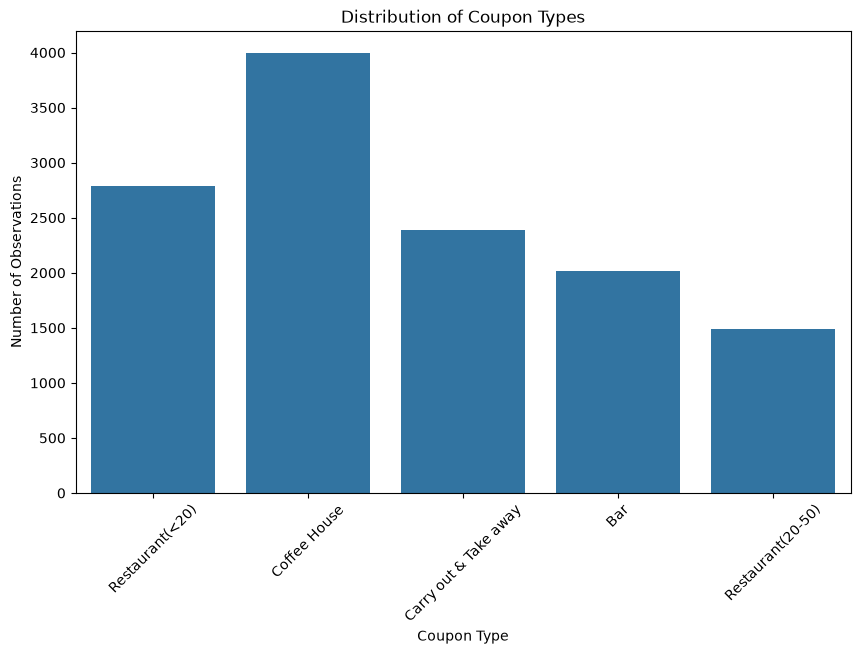

In [25]:
#5. Use a bar plot to visualize the `coupon` column.
plt.figure(figsize=(10,6))
sns.countplot(data=data, x="coupon")
plt.title("Distribution of Coupon Types")
plt.xlabel("Coupon Type")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.show()

In [26]:
#6. Use a histogram to visualize the temperature column.
data["temperature"].value_counts()

temperature
80    6528
55    3840
30    2316
Name: count, dtype: int64

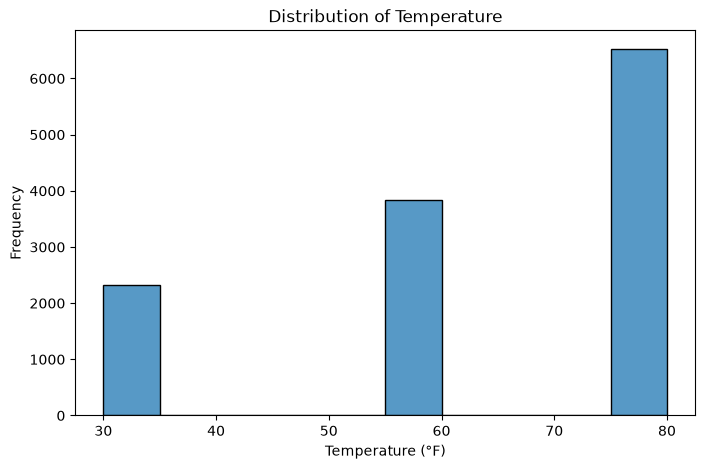

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="temperature", bins=10)
plt.title("Distribution of Temperature")
plt.xlabel("Temperature (°F)")
plt.ylabel("Frequency")
plt.show()

In [28]:
 #1. Second section ======>
#Create a new `DataFrame` that contains just the bar coupons.
bar_data = data[data["coupon"]=="Bar"]
bar_data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,Unknown,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,Unknown,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,Unknown,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1


In [29]:
#2. What proportion of bar coupons were accepted?
bar_data["Y"].value_counts(normalize=True)*100

Y
0    58.998513
1    41.001487
Name: proportion, dtype: float64

In [30]:
#3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.
bar_3_or_less = bar_data[
    bar_data["Bar"].isin(["never", "less1", "1~3"])]
bar_more_than_3 = bar_data[
    bar_data["Bar"].isin(["4~8", "gt8"])]
rate_3_or_less = bar_3_or_less["Y"].mean() * 100

rate_more_than_3 = bar_more_than_3["Y"].mean() * 100

print(f"3 or fewer visits: {rate_3_or_less:.2f}%")
print(f"More than 3 visits: {rate_more_than_3:.2f}%")


3 or fewer visits: 37.06%
More than 3 visits: 76.88%


In [31]:
#4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others. Is there a difference?
bar_data["age"].value_counts()
group1 = bar_data[
    (bar_data["Bar"].isin(["1~3", "4~8", "gt8"])) & (bar_data["age"].isin(["26", "31", "36", "41", "46", "50plus"]))]
group2 = bar_data.drop(group1.index)
rate_group1 = group1["Y"].mean() * 100
rate_group2 = group2["Y"].mean() * 100

print(f"Group 1 acceptance rate: {rate_group1:.2f}%")
print(f"Group 2 acceptance rate: {rate_group2:.2f}%")

Group 1 acceptance rate: 69.52%
Group 2 acceptance rate: 33.50%


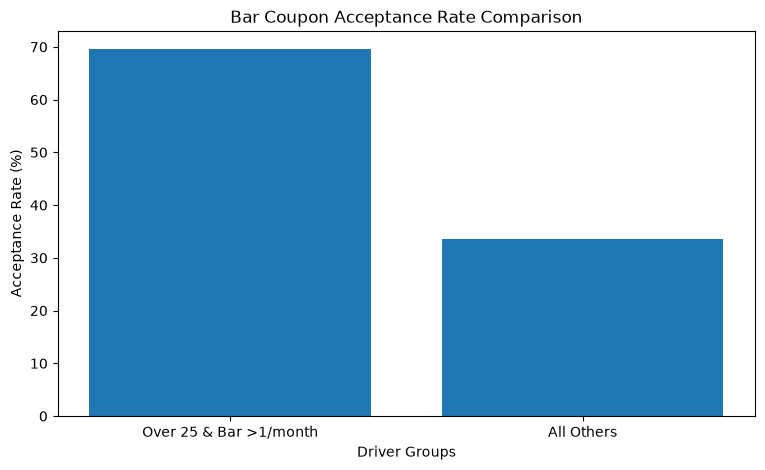

In [32]:
groups = ["Over 25 & Bar >1/month", "All Others"]
rates = [rate_group1, rate_group2]
plt.figure(figsize=(9, 5))
plt.bar(groups, rates)
plt.title("Bar Coupon Acceptance Rate Comparison")
plt.xlabel("Driver Groups")
plt.ylabel("Acceptance Rate (%)")
plt.show()

<ArrowStringArray>
['never', 'less1', '1~3', 'gt8', 'Unknown', '4~8']
Length: 6, dtype: str
<ArrowStringArray>
['Kid(s)', 'Alone', 'Friend(s)', 'Partner']
Length: 4, dtype: str
<ArrowStringArray>
[                               'Unemployed',
                'Architecture & Engineering',
                                   'Student',
                'Education&Training&Library',
                        'Healthcare Support',
      'Healthcare Practitioners & Technical',
                           'Sales & Related',
                                'Management',
  'Arts Design Entertainment Sports & Media',
                   'Computer & Mathematical',
              'Life Physical Social Science',
                   'Personal Care & Service',
               'Community & Social Services',
           'Office & Administrative Support',
                 'Construction & Extraction',
                                     'Legal',
                                   'Retired',
         'Installation

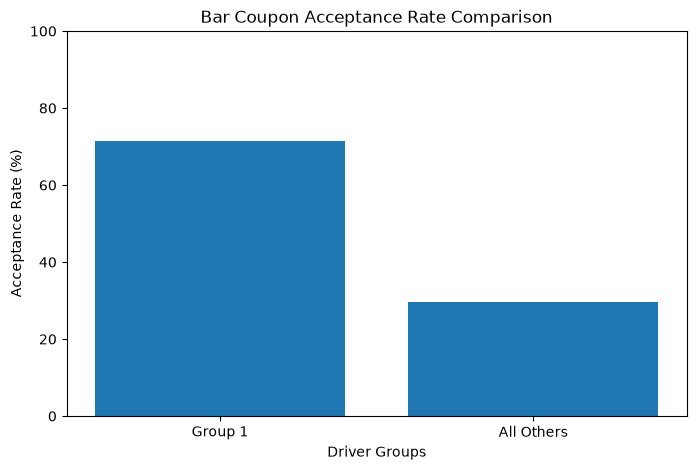

In [36]:
#5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.
print(bar_data["Bar"].unique())
print(bar_data["passanger"].unique())
print(bar_data["occupation"].unique())
group1 = bar_data[
    (bar_data["Bar"].isin(["1~3", "4~8", "gt8"])) &
    (bar_data["passanger"] != "Kid(s)") &
    (bar_data["occupation"] != "Farming Fishing & Forestry")
]
group2 = bar_data.drop(group1.index)
rate_group1 = group1["Y"].mean() * 100
rate_group2 = group2["Y"].mean() * 100
print(f"Group 1 acceptance rate: {rate_group1:.2f}%")
print(f"Group 2 acceptance rate: {rate_group2:.2f}%")
groups = ["Group 1", "All Others"]
rates = [rate_group1, rate_group2]
plt.figure(figsize=(8, 5))
plt.bar(groups, rates)
plt.title("Bar Coupon Acceptance Rate Comparison")
plt.xlabel("Driver Groups")
plt.ylabel("Acceptance Rate (%)")
plt.ylim(0, 100)
plt.show()

In [37]:
#6. Compare the acceptance rates between those drivers who:go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*go to bars more than once a month and are under the age of 30 *OR*o to cheap restaurants more than 4 times a month and income is less than 50K.
print(bar_data["maritalStatus"].unique())
print(bar_data["age"].unique())
print(bar_data["RestaurantLessThan20"].unique())
print(bar_data["income"].unique())


<ArrowStringArray>
['Unmarried partner', 'Single', 'Married partner', 'Divorced', 'Widowed']
Length: 5, dtype: str
<ArrowStringArray>
['21', '46', '26', '31', '41', '50plus', '36', 'below21']
Length: 8, dtype: str
<ArrowStringArray>
['4~8', '1~3', 'less1', 'gt8', 'Unknown', 'never']
Length: 6, dtype: str
<ArrowStringArray>
[ '$37500 - $49999',  '$62500 - $74999',  '$12500 - $24999',
  '$75000 - $87499',  '$50000 - $62499',  '$25000 - $37499',
  '$100000 or More',  '$87500 - $99999', 'Less than $12500']
Length: 9, dtype: str


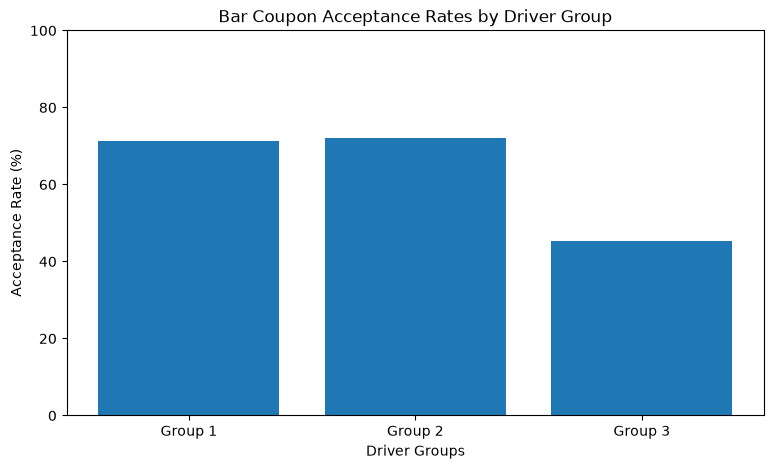

     Group  Acceptance Rate (%)
0  Group 1            71.324864
1  Group 2            72.173913
2  Group 3            45.348837


In [39]:
group1 = bar_data[
    (bar_data["Bar"].isin(["1~3", "4~8", "gt8"])) &
    (bar_data["passanger"] != "Kid(s)") &
    (bar_data["maritalStatus"] != "Widowed")
]
group2 = bar_data[
    (bar_data["Bar"].isin(["1~3", "4~8", "gt8"])) &
    (bar_data["age"].isin(["below21", "21", "26"]))
]
group3 = bar_data[
    (bar_data["RestaurantLessThan20"].isin(["4~8", "gt8"])) &
    (bar_data["income"].isin([
        "Less than $12500",
        "$12500 - $24999",
        "$25000 - $37499",
        "$37500 - $49999"
    ]))
]
rate1 = group1["Y"].mean() * 100
rate2 = group2["Y"].mean() * 100
rate3 = group3["Y"].mean() * 100

groups = ["Group 1", "Group 2", "Group 3"]
rates = [rate1, rate2, rate3]
plt.figure(figsize=(9, 5))
plt.bar(groups, rates)
plt.title("Bar Coupon Acceptance Rates by Driver Group")
plt.xlabel("Driver Groups")
plt.ylabel("Acceptance Rate (%)")
plt.ylim(0, 100)
plt.show()
comparison = pd.DataFrame({
    "Group": ["Group 1", "Group 2", "Group 3"],
    "Acceptance Rate (%)": [rate1, rate2, rate3]
})

print(comparison)

In [ ]:
#7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?
Based on the analysis, I hypothesize that drivers who frequently visit bars are more likely to accept Bar coupons than those who rarely visit bars. 
Drivers who travel without children and regularly visit bars also appear more likely to accept these coupons.
Age, marital status, income, and dining habits may influence coupon acceptance as well. 
However, the strongest pattern appears to be the frequency of bar visits.